### imprting Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### getting data

In [26]:
df=pd.read_csv('../dataset/olist_products_dataset.csv')
df.head(2)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0


### inference
1) product_id to link tables with each other and uniquely indentify the products.
2) product_category_name, product_name_lenght, product_description_lenght deliver product information.
3) product_photos_qty number of photos available on platform.
4) product_weight_g is weight of product in grams.
5) product_length_cm, product_height_cm, product_width_cm are product dimensions.

In [27]:
df.shape

(32951, 9)

In [28]:
df.dtypes

product_id                     object
product_category_name          object
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object

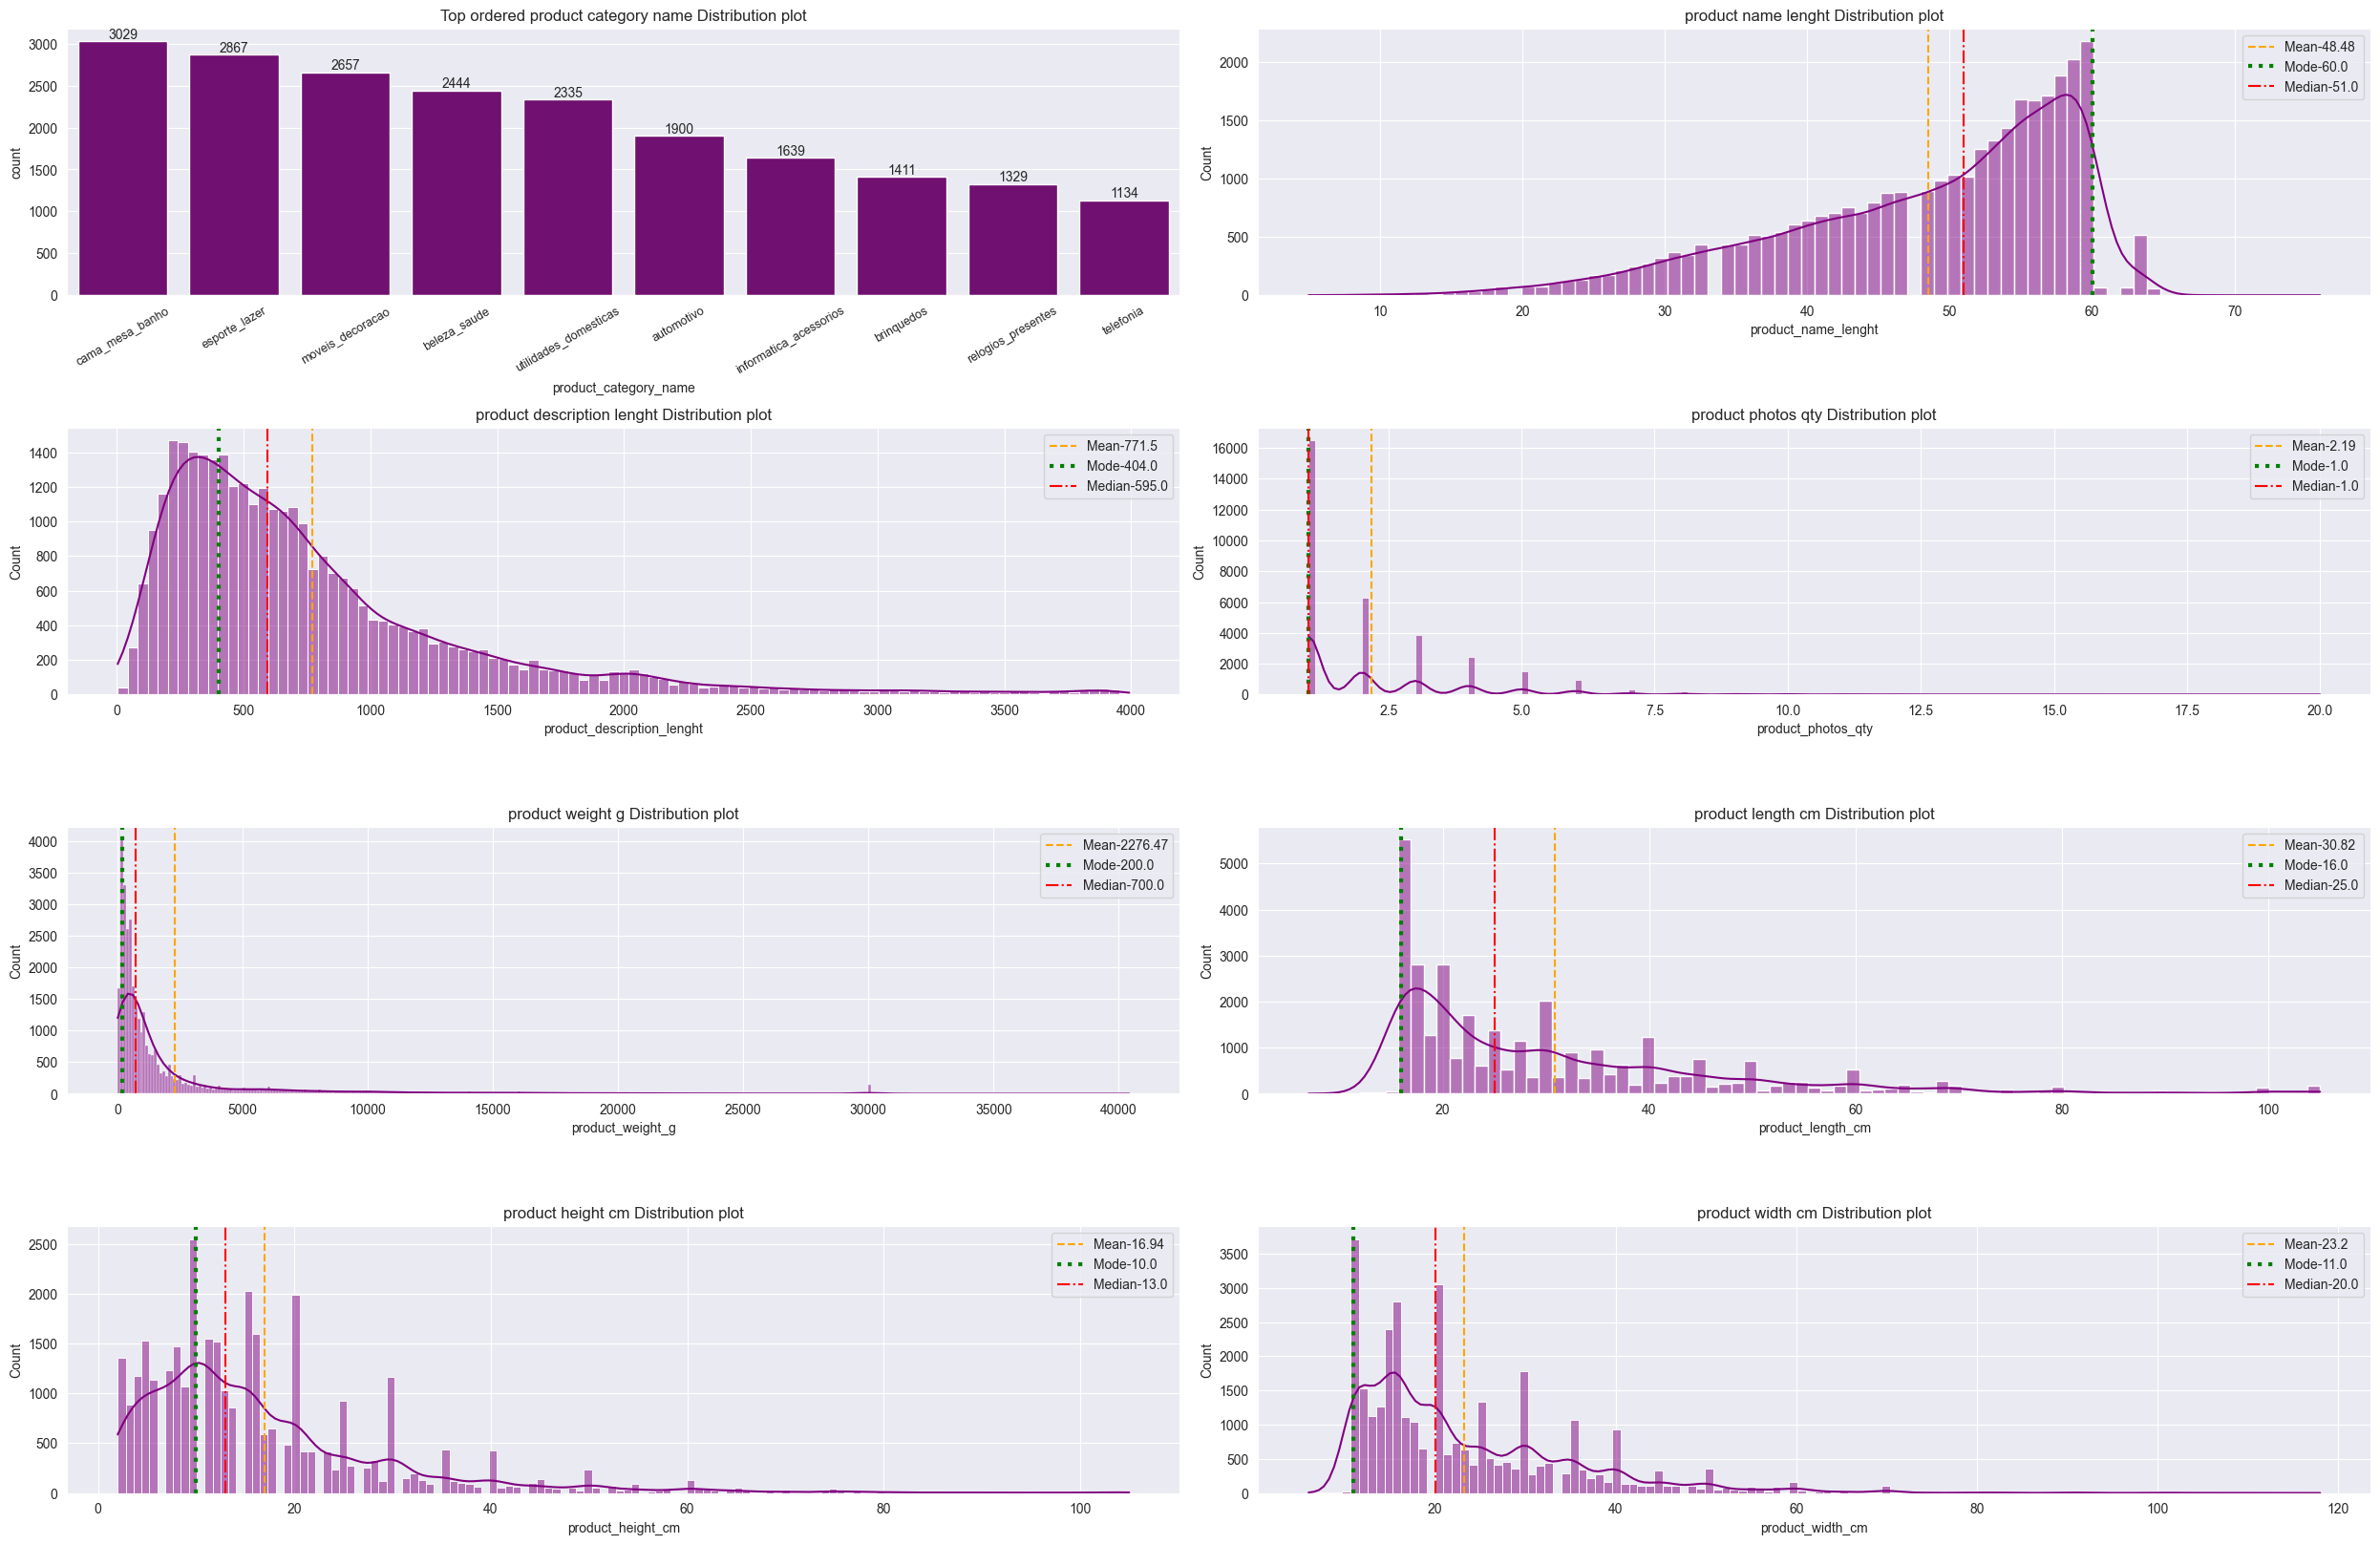

In [50]:
sns.set_style('darkgrid')
plt.figure(figsize=(25,20))
cols=list(df.columns)
cols=cols[1:]
for i in range(len(cols)):
    plt.subplot(len(cols)//2+1,2,i+1)
    if df[cols[i]].dtypes=='object':
        x1=df['product_category_name'].value_counts().reset_index().sort_values(by='count',ascending=False)
        x1=x1.iloc[:10,:]
        ax=sns.barplot(data=x1,x='product_category_name',y='count',color='purple')
        plt.xticks(rotation=30,fontsize=9)
        plt.bar_label(ax.containers[0])
        plt.title(f"Top ordered {cols[i].replace("_"," ")} Distribution plot")
        plt.tight_layout()
    else:
        sns.histplot(data=df,x=cols[i],kde=True,color='purple')
        plt.axvline(df[cols[i]].mean(),linestyle='--',color='orange',label=f'Mean-{df[cols[i]].mean().round(2)}')
        plt.axvline(df[cols[i]].mode()[0],linestyle=':',color='green',linewidth=3,label=f'Mode-{df[cols[i]].mode()[0]}')
        plt.axvline(df[cols[i]].median(),linestyle='-.',color='Red',label=f'Median-{df[cols[i]].median()}')
        plt.title(f"{cols[i].replace("_"," ")} Distribution plot")
        plt.legend()
plt.tight_layout(pad=1)
plt.savefig('products_insights.png',dpi=500,bbox_inches="tight")
plt.show()